In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [65]:
df = pd.read_csv('loan.csv', low_memory=False)
#delete entry with share of application_type < 0.05
# print(null_share.idxmax())
# print(null_share.max().round(2))
# null_share.sort_values(ascending=False).head(5)

df = df[df['application_type'] == 'INDIVIDUAL']
df = df.reset_index(drop=True)

policy_code            1
term                   2
initial_list_status    2
pymnt_plan             2
application_type       2
dtype: int64

In [60]:
#delete cols with share of nan > 0.2
print(df.shape)
null_share = df.isna().mean()
cols_to_drop = null_share[null_share > 0.2].index
#cols_to_drop
df = df.drop(columns=cols_to_drop)
#df_without_null_col
print(df.shape)

(887379, 52)
(887379, 52)


In [5]:
#unique in grade, home_ownership, vetification_status, pymnt_plan
for col in ['grade', 'home_ownership', 'verification_status', 'pymnt_plan']:
    print(f"{col} : count of unique: \n {df[col].value_counts()} \n share: \n {df[col].value_counts(normalize=True)}") 


grade : count of unique: 
 grade
B    254433
C    245717
A    148184
D    139419
E     70614
F     23022
G      5479
Name: count, dtype: int64 
 share: 
 grade
B    0.286889
C    0.277062
A    0.167087
D    0.157204
E    0.079622
F    0.025959
G    0.006178
Name: proportion, dtype: float64
home_ownership : count of unique: 
 home_ownership
MORTGAGE    443203
RENT        355995
OWN          87435
OTHER          182
NONE            50
ANY              3
Name: count, dtype: int64 
 share: 
 home_ownership
MORTGAGE    0.499740
RENT        0.401407
OWN         0.098589
OTHER       0.000205
NONE        0.000056
ANY         0.000003
Name: proportion, dtype: float64
verification_status : count of unique: 
 verification_status
Source Verified    329424
Verified           290810
Not Verified       266634
Name: count, dtype: int64 
 share: 
 verification_status
Source Verified    0.371446
Verified           0.327907
Not Verified       0.300647
Name: proportion, dtype: float64
pymnt_plan : count o

In [66]:
#delete columns with number of unique value < 10 and a strong skew in the distribution of values
df.nunique()
nunique_cols_to_drop = []
for col in df.columns:
    if df[col].nunique() < 10:
        if df[col].value_counts(normalize=True).iloc[0] > 0.8:
            nunique_cols_to_drop.append(col)
print(nunique_cols_to_drop)
df = df.drop(columns=nunique_cols_to_drop)

pymnt_plan
policy_code
application_type
acc_now_delinq
['pymnt_plan', 'policy_code', 'application_type', 'acc_now_delinq']


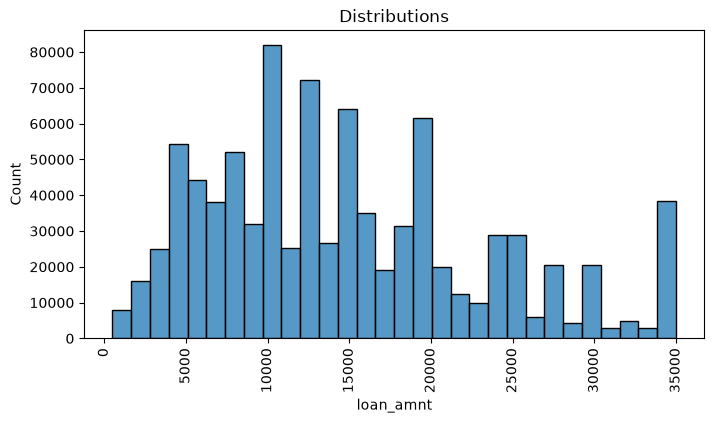

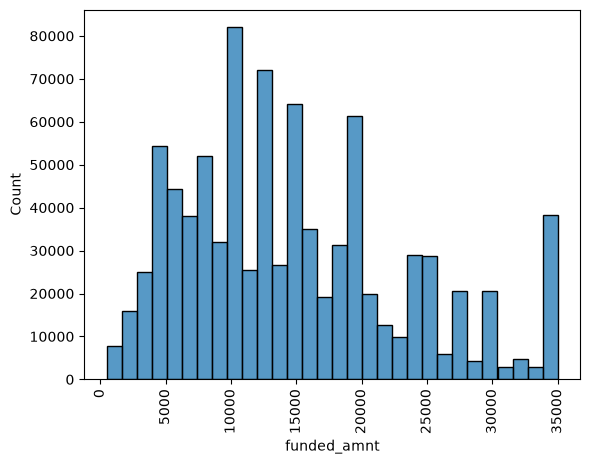

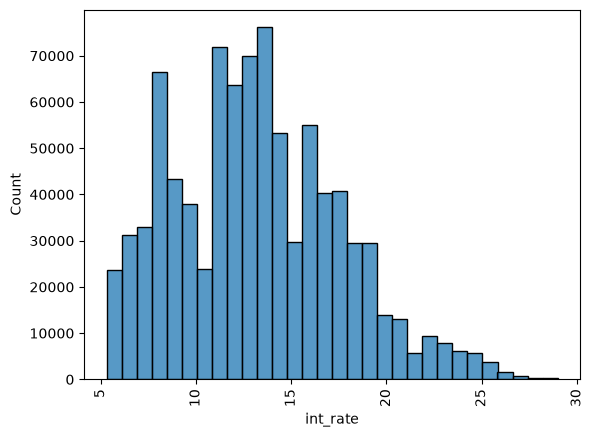

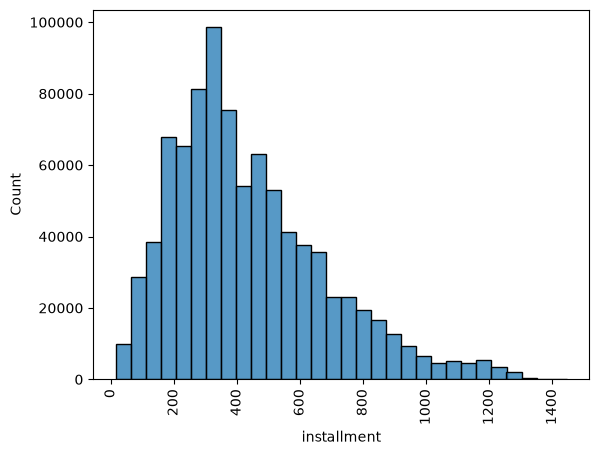

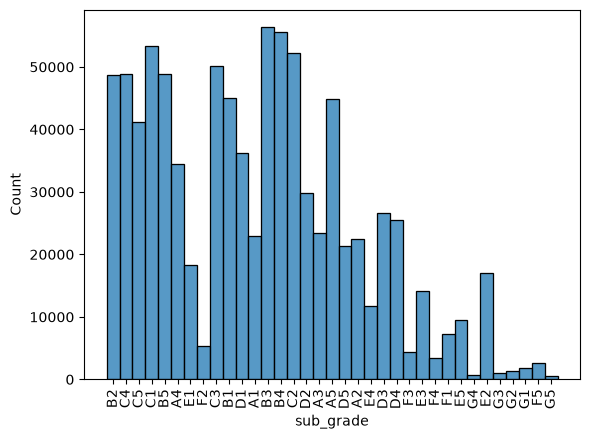

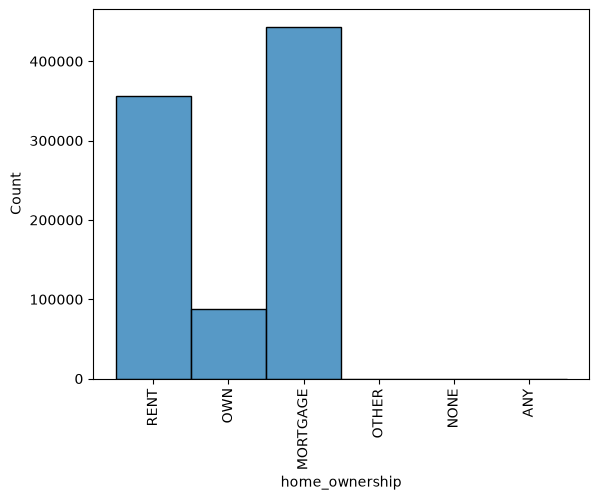

13000.0


In [67]:


#Distribution of values: 'loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'sub_grade', 'home_ownership';
plt.figure(figsize=(8, 4))
plt.title('Distributions')
for col in ['loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'sub_grade', 'home_ownership']:
    plt.xticks(rotation=90)
    sns.histplot(data=df, x=f'{col}', bins=30)
    plt.show()

In [8]:
df['loan_amnt'].max()

np.float64(35000.0)

In [9]:
df['loan_amnt'].min()

np.float64(500.0)

In [10]:
df['loan_amnt'].mean()

np.float64(14752.593452464178)

In [70]:
df['loan_amnt'].median()

np.float64(13000.0)

In [12]:
df['loan_amnt'].std()

np.float64(8434.363707089176)

In [13]:
df['loan_amnt'].quantile([0.01, 0.05, 0.95, 0.99])

0.01     1800.0
0.05     3600.0
0.95    32000.0
0.99    35000.0
Name: loan_amnt, dtype: float64

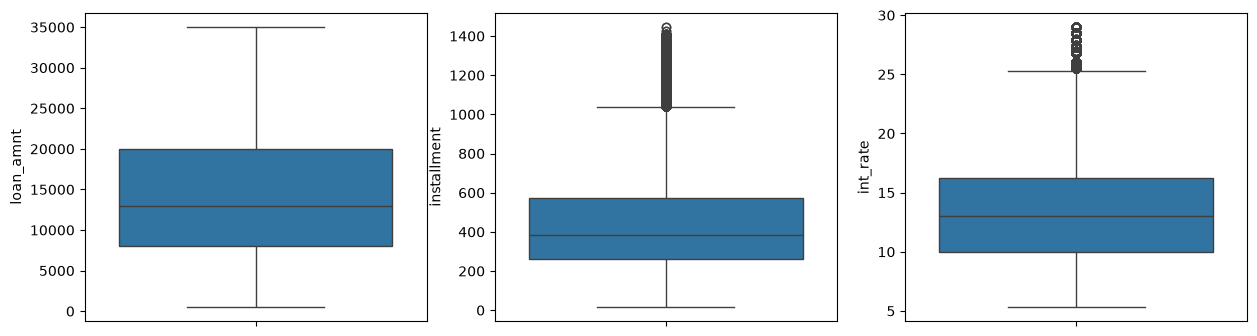

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for i, col in enumerate(['loan_amnt', 'installment', 'int_rate']):
    sns.boxplot(data=df, y=f'{col}', ax=axes[i])

In [15]:
df['loan_status'].value_counts()

loan_status
Current                                                601338
Fully Paid                                             207722
Charged Off                                             45248
Late (31-120 days)                                      11589
Issued                                                   8396
In Grace Period                                          6250
Late (16-30 days)                                        2357
Does not meet the credit policy. Status:Fully Paid       1988
Default                                                  1219
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

In [20]:
df['dti'].describe()

count    886868.000000
mean         18.126316
std           8.298625
min           0.000000
25%          11.910000
50%          17.650000
75%          23.940000
max          39.990000
Name: dti, dtype: float64

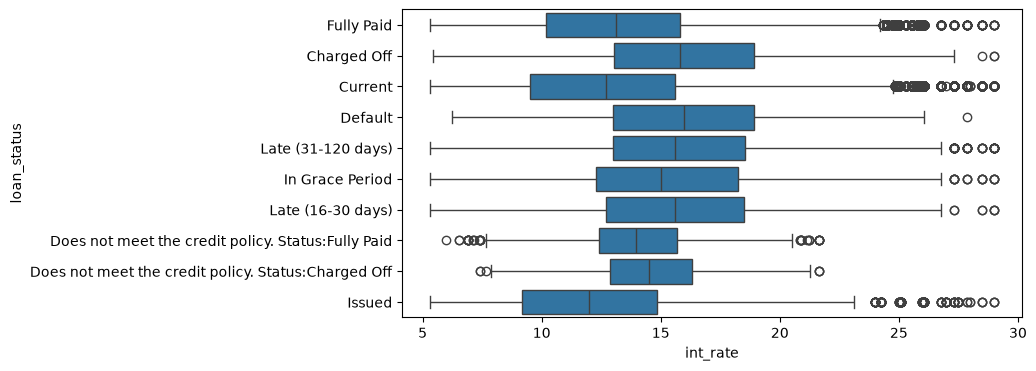

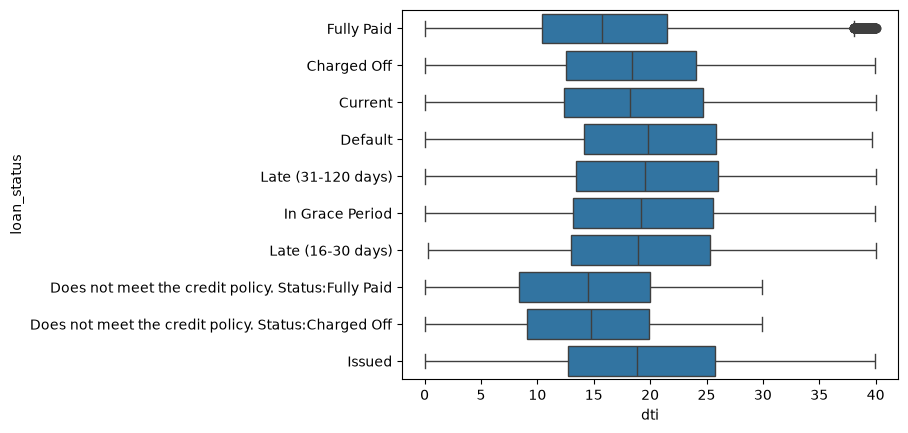

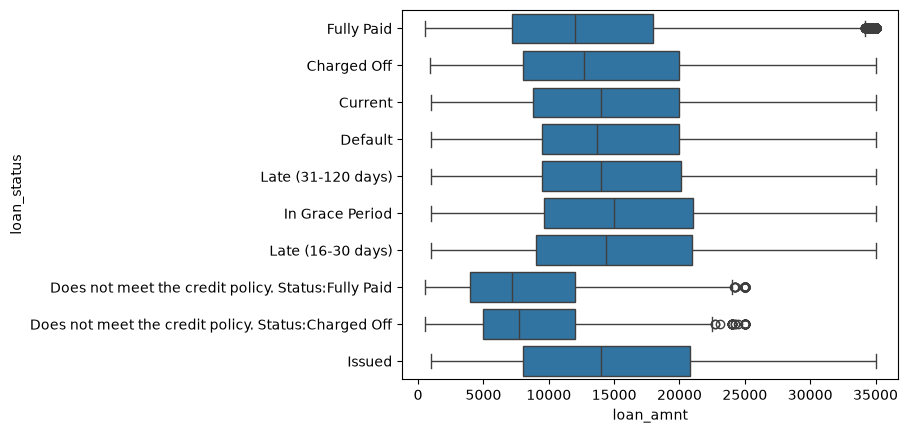

In [31]:
plt.figure(figsize=(8,4))
for i, col in enumerate(['int_rate', 'dti', 'loan_amnt']):
    sns.boxplot(data=df, x=f'{col}', y='loan_status')
    plt.show()

In [26]:
df.groupby('loan_status')['annual_inc'].median()

loan_status
Charged Off                                            56000.0
Current                                                65000.0
Default                                                56000.0
Does not meet the credit policy. Status:Charged Off    54000.0
Does not meet the credit policy. Status:Fully Paid     57000.0
Fully Paid                                             64169.0
In Grace Period                                        64000.0
Issued                                                 67000.0
Late (16-30 days)                                      62000.0
Late (31-120 days)                                     60000.0
Name: annual_inc, dtype: float64

In [33]:
df['int_rate'].describe()

count    886868.000000
mean         13.245630
std           4.381677
min           5.320000
25%           9.990000
50%          12.990000
75%          16.200000
max          28.990000
Name: int_rate, dtype: float64

<Axes: xlabel='annual_inc', ylabel='loan_status'>

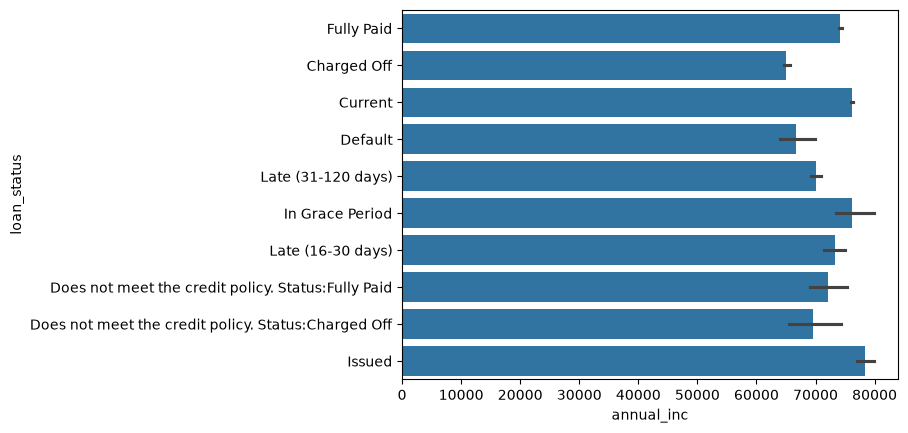

In [35]:
sns.barplot(data=df, x='annual_inc', y='loan_status')

In [36]:
df.groupby('loan_status')['annual_inc'].agg(['mean', 'median'])

,mean,median
loan_status,,
Charged Off,65085.132717,56000.0
Current,76166.384461,65000.0
Default,66754.126612,56000.0
Does not meet the credit policy. Status:Charged Off,69525.915033,54000.0
Does not meet the credit policy. Status:Fully Paid,72145.418271,57000.0
Fully Paid,74162.061866,64169.0
In Grace Period,76147.612694,64000.0
Issued,78402.083072,67000.0
Late (16-30 days),73279.117959,62000.0


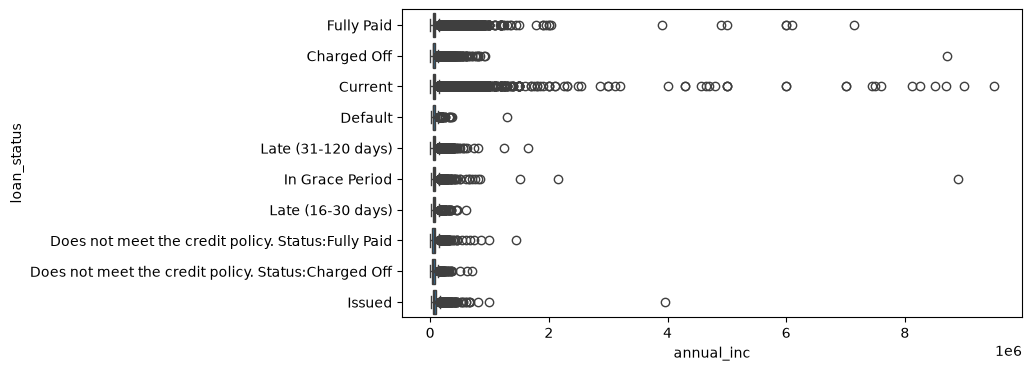

In [38]:
sns.boxplot(data=df, x='annual_inc', y='loan_status')

<Axes: >

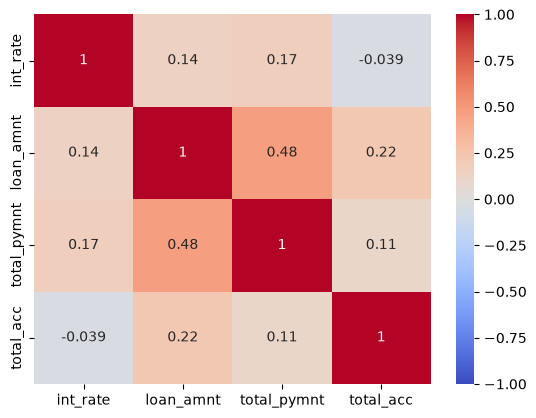

In [40]:
corr = df[['int_rate', 'loan_amnt', 'total_pymnt', 'total_acc']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)

In [41]:
corr.unstack().sort_values(ascending=False)

int_rate     int_rate       1.000000
loan_amnt    loan_amnt      1.000000
total_acc    total_acc      1.000000
total_pymnt  total_pymnt    1.000000
loan_amnt    total_pymnt    0.475195
total_pymnt  loan_amnt      0.475195
total_acc    loan_amnt      0.222657
loan_amnt    total_acc      0.222657
total_pymnt  int_rate       0.170825
int_rate     total_pymnt    0.170825
             loan_amnt      0.144827
loan_amnt    int_rate       0.144827
total_acc    total_pymnt    0.109109
total_pymnt  total_acc      0.109109
int_rate     total_acc     -0.038620
total_acc    int_rate      -0.038620
dtype: float64

<Axes: xlabel='loan_amnt', ylabel='total_pymnt'>

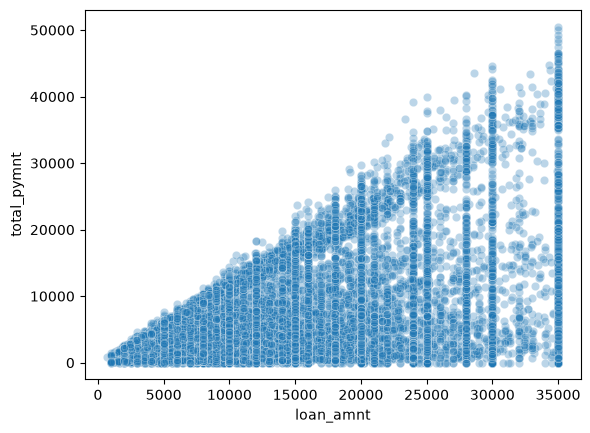

In [51]:
sns.scatterplot(data=df.sample(20000), x='loan_amnt', y='total_pymnt' , alpha=0.3)

<Axes: xlabel='total_acc', ylabel='loan_amnt'>

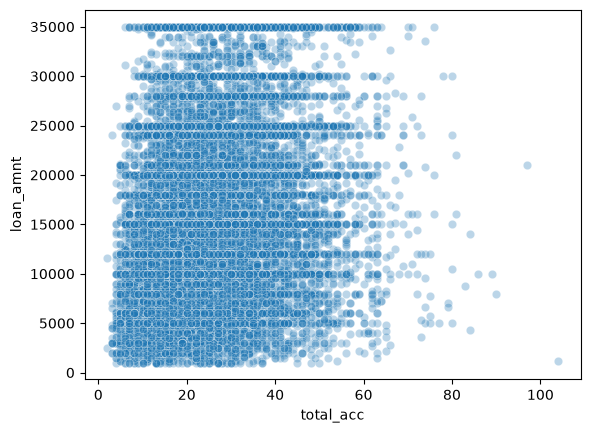

In [52]:
sns.scatterplot(data=df.sample(20000), x='total_acc', y='loan_amnt', alpha=0.3)